# Análisis exploratorio de datos

Contentesta las siguientes preguntas escribiendo el código de Python necesario para encontrar las respuestas o producir las gráficas necesarias

---


In [4]:
# No mostrar advertencias
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('./data/retailmax.csv')

In [5]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


### 1. ¿Cuál es la distribución de edades de los clientes?
- **Objetivo**: Comprender la distribución de las edades en el conjunto de datos.
- **Respuesta esperada**: Un histograma de la columna Age.

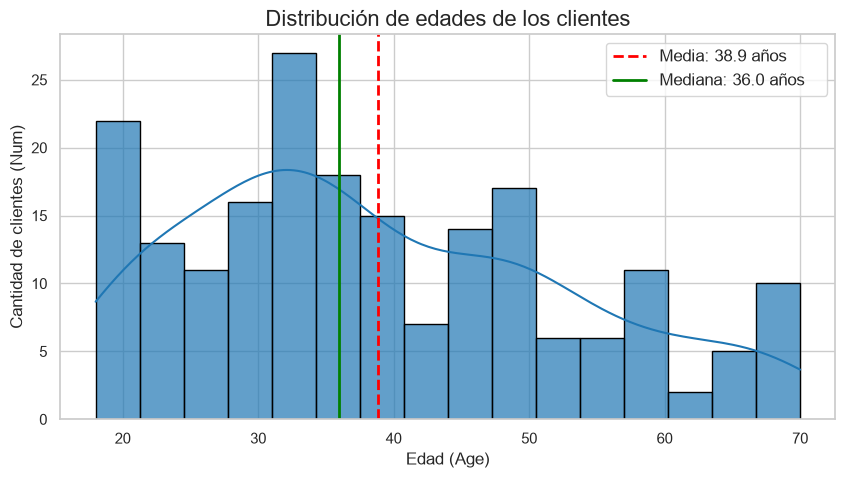

In [6]:

sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))
sns.histplot(df['Age'], bins=16, kde=True, color='#1f77b4', edgecolor='black', alpha=0.7)
plt.title('Distribución de edades de los clientes', fontsize=16)
plt.xlabel('Edad (Age)')
plt.ylabel('Cantidad de clientes (Num)')
plt.axvline(df['Age'].mean(), color='red',linestyle="--", linewidth=2, label=f'Media: {df["Age"].mean():.1f} años   ')
plt.axvline(df['Age'].median(), color='green',linestyle="-", linewidth=2, label=f'Mediana: {df["Age"].median():.1f} años   ')
plt.legend(fontsize=12 )    
plt.show()

### 2. ¿Existen diferencias significativas en los ingresos anuales entre hombres y mujeres?
- **Objetivo**: Comparar la distribución de ingresos anuales entre géneros.
- **Respuesta esperada**: Una gráfica de cajas (boxplot) que muestre la distribución de Annual Income (k$) por género.

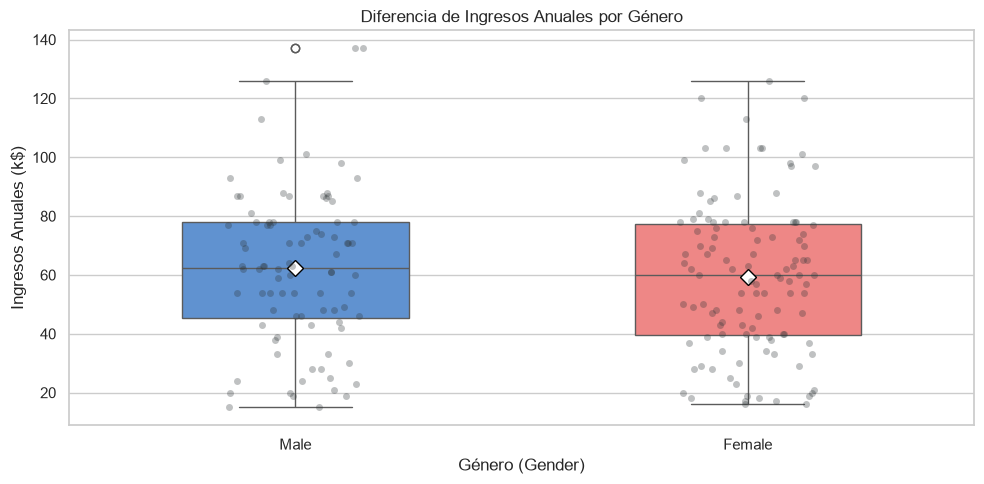

In [7]:

plt.figure(figsize=(10, 5))

sns.boxplot( 
    data=df,
    x='Gender',
    y='Annual Income (k$)',
    palette={'Male': '#4e90e2', 'Female': '#ff7675'},
    width=0.5,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor":"black", "markersize": 8},
)

sns.stripplot(
    data=df,
    x='Gender',
    y='Annual Income (k$)',
    color='#2d3436',
    alpha=0.3,
    jitter=0.15,
    size=5,
)

plt.title("Diferencia de Ingresos Anuales por Género",)
plt.xlabel('Género (Gender)')
plt.ylabel('Ingresos Anuales (k$)')

plt.tight_layout()
plt.show()  

### 3. ¿Cómo se distribuye la puntuación de gasto (Spending Score) entre los diferentes rangos de edad?
- **Objetivo**: Analizar la relación entre la edad y la puntuación de gasto.
- **Respuesta esperada**: Una gráfica de dispersión (scatter plot) o un gráfico de cajas que compare la Spending Score (1-100) con diferentes grupos de edad.

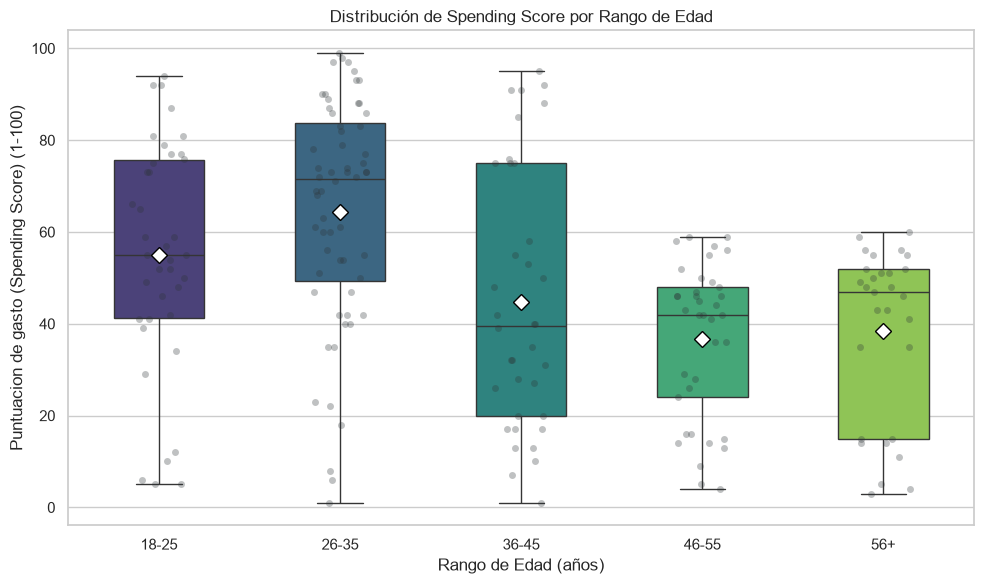

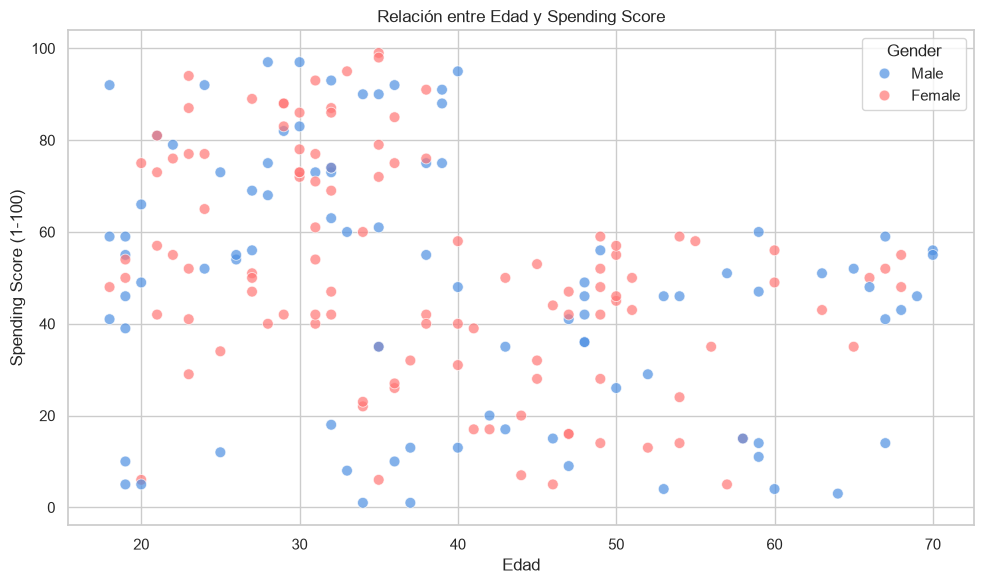

In [8]:
bins = [18, 26, 36, 46, 56,80]
etiquetas = ['18-25', '26-35', '36-45', '46-55', '56+']
df['Rango de Edad'] = pd.cut(df['Age'], bins=bins, labels=etiquetas, right=False)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Rango de Edad',
    y='Spending Score (1-100)',
    hue='Rango de Edad',
    palette='viridis',
    legend=False,
    dodge=False,
    width=0.5,
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 8},
)

sns.stripplot(
    data=df,
    x='Rango de Edad',
    y='Spending Score (1-100)',
    color='#2d3436',
    alpha=0.3,
    jitter=0.15,
    size=5,
)

plt.title("Distribución de Spending Score por Rango de Edad")
plt.xlabel("Rango de Edad (años)")
plt.ylabel("Puntuacion de gasto (Spending Score) (1-100)")

plt.tight_layout()
plt.show()

# 3. Scatter plot (alternativa o complemento)
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Age',
    y='Spending Score (1-100)',
    hue='Gender',
    palette={'Male': '#4e90e2', 'Female': '#ff7675'},
    alpha=0.7,
    s=60,
)

plt.title("Relación entre Edad y Spending Score")
plt.xlabel("Edad")
plt.ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

### 4. ¿Cuál es la correlación entre el ingreso anual y la puntuación de gasto?
- **Objetivo**: Identificar si existe una relación lineal entre el ingreso y el gasto.
- **Respuesta esperada**: Una gráfica de dispersión y el cálculo del coeficiente de correlación entre Annual Income (k$) y Spending Score (1-100).

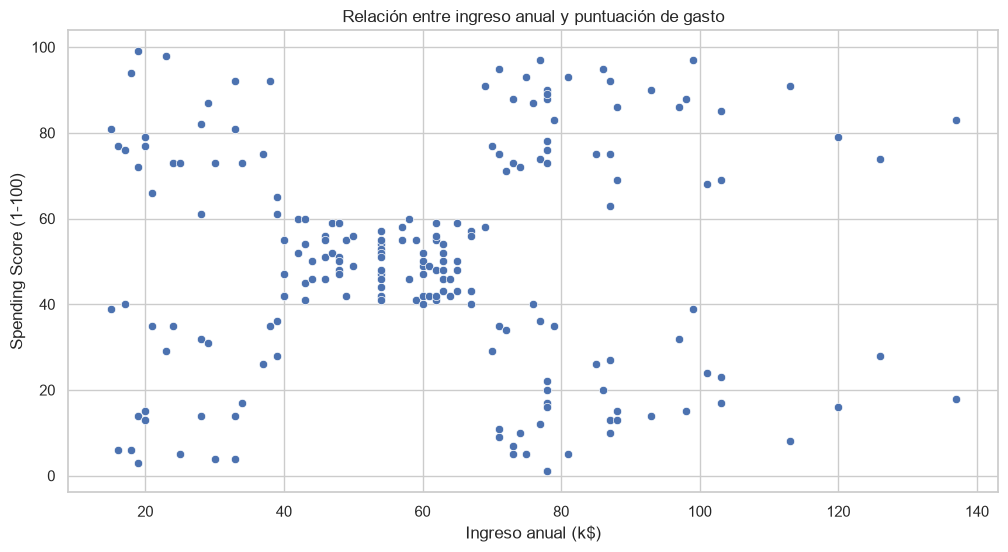

Coeficiente de correlación: 0.009902848094037617


In [11]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)'
)

plt.title('Relación entre ingreso anual y puntuación de gasto')
plt.xlabel('Ingreso anual (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

correlacion = df['Annual Income (k$)'].corr(
    df['Spending Score (1-100)']
)

print("Coeficiente de correlación:", correlacion)

### 5. ¿Cómo varía la puntuación de gasto en diferentes grupos de ingresos anuales?
- **Objetivo**: Examinar cómo los clientes en diferentes rangos de ingresos se comportan en términos de gasto.
- **Respuesta esperada**: Una gráfica de cajas o de violín que muestre la Spending Score (1-100) para diferentes rangos de Annual Income (k$).

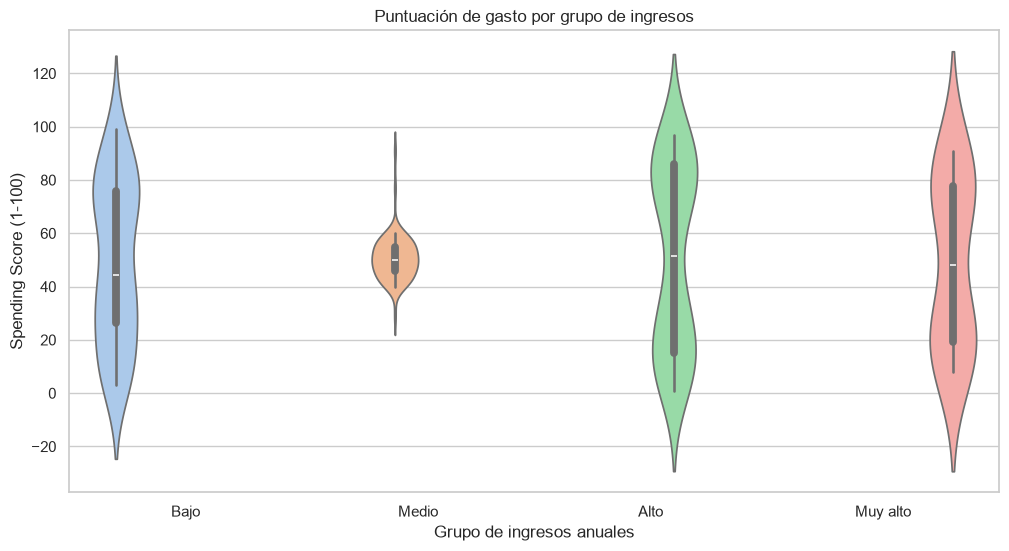

In [13]:
df['Income Group'] = pd.cut(
    df['Annual Income (k$)'],
    bins=[0, 40, 70, 100, 150],
    labels=['Bajo', 'Medio', 'Alto', 'Muy alto']
)
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df,
    x='Income Group',
    y='Spending Score (1-100)',
    hue='Income Group',
    palette='pastel',
    legend=False
)

plt.title('Puntuación de gasto por grupo de ingresos')
plt.xlabel('Grupo de ingresos anuales')
plt.ylabel('Spending Score (1-100)')
plt.show()

### 6. ¿Cuál es la proporción de clientes por género?
- **Objetivo**: Determinar el balance de género en el conjunto de datos.
- **Respuesta esperada**: Una gráfica de barras o un gráfico de pastel que muestre la proporción de hombres y mujeres.

In [ ]:
proporcion = df['Gender'].value_counts(normalize=True) * 100

plt.pie(
    proporcion,
    autopct='%1.1f%%',
    colors=['#FF9999', '#99CCFF'],
    startangle=90
)

plt.title('Proporción de clientes por género')
plt.show()  

TypeError: pie() missing 1 required positional argument: 'x'

### 7. ¿Qué grupos de edad gastan más en promedio?
- **Objetivo**: Identificar los grupos de edad que tienen una mayor puntuación de gasto en promedio.
- **Respuesta esperada**: Una gráfica de barras que compare la puntuación de gasto promedio entre diferentes grupos de edad.

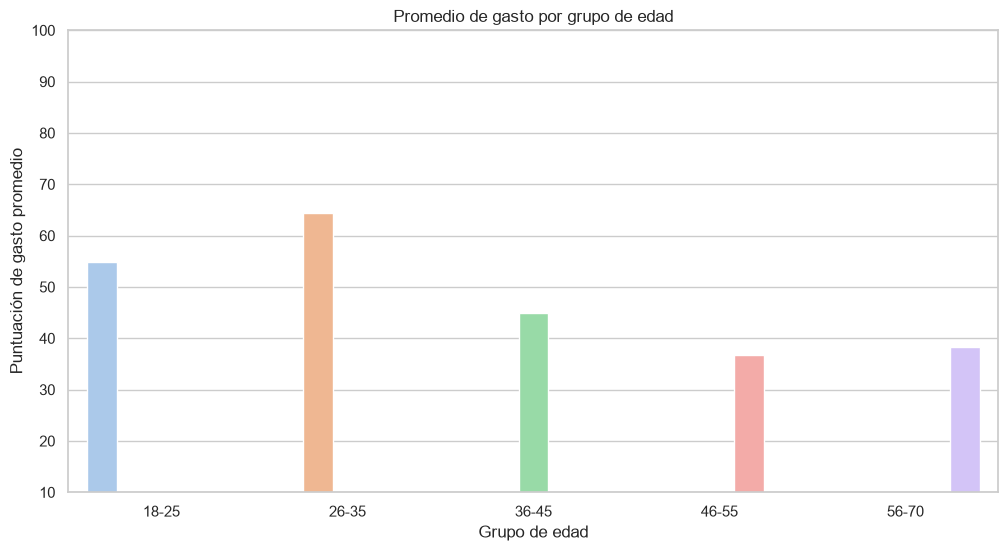

In [32]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 70],
    labels=['18-25', '26-35', '36-45', '46-55', '56-70']
)
promedio_gasto = df.groupby(
    'Age Group', observed=True
)['Spending Score (1-100)'].mean()
plt.figure(figsize=(12, 6))

sns.barplot(
    x=promedio_gasto.index,
    y=promedio_gasto.values,
    hue=promedio_gasto.index,
    palette='pastel',
    legend=False
)

plt.title('Promedio de gasto por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Puntuación de gasto promedio')
plt.ylim(10, 100)
plt.show()

### 8. ¿Hay alguna relación entre la edad y el ingreso anual de los clientes?
- **Objetivo**: Explorar si hay una tendencia entre la edad de los clientes y sus ingresos.
- **Respuesta esperada**: Una gráfica de dispersión que muestre la relación entre Age y Annual Income (k$).

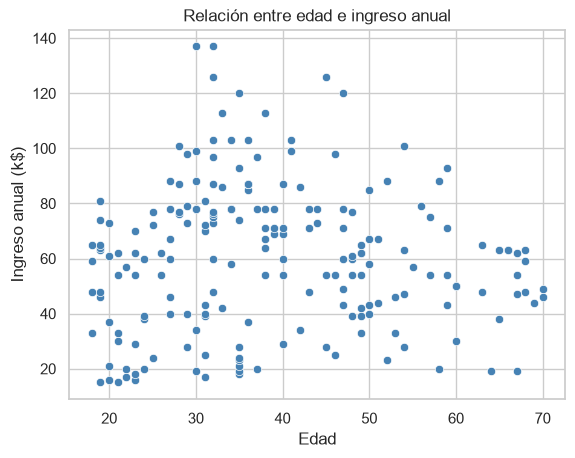

Coeficiente de correlación: -0.012398042736060167


In [33]:
sns.scatterplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    color='steelblue'
)

plt.title('Relación entre edad e ingreso anual')
plt.xlabel('Edad')
plt.ylabel('Ingreso anual (k$)')
plt.show()
correlacion = df['Age'].corr(df['Annual Income (k$)'])

print("Coeficiente de correlación:", correlacion)

### 9. ¿Cuál es la distribución conjunta de la edad y el ingreso anual?
- **Objetivo**: Entender cómo se distribuyen estas dos variables en conjunto.
- **Respuesta esperada**: Una gráfica de dispersión con una densidad de puntos o un gráfico de hexágonos que muestre la distribución conjunta de Age y Annual Income (k$).

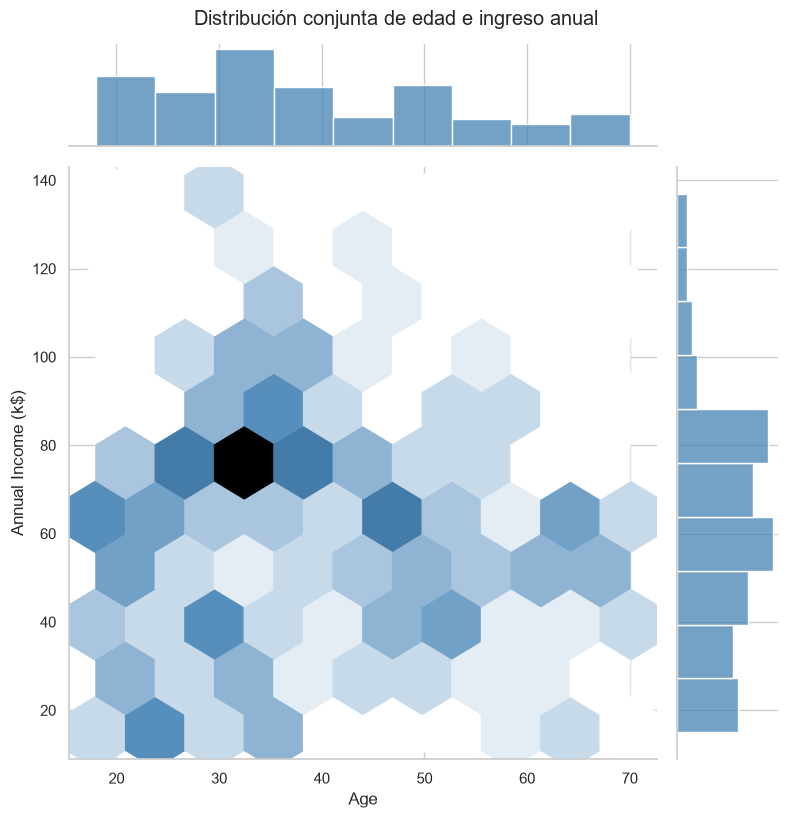

In [34]:
sns.jointplot(
    data=df,
    x='Age',
    y='Annual Income (k$)',
    kind='hex',
    color='steelblue',
    height=8
)

plt.suptitle('Distribución conjunta de edad e ingreso anual', y=1.02)
plt.show()

### 10. ¿Cómo se distribuyen los clientes en función de la puntuación de gasto y el género?
- **Objetivo**: Analizar la relación entre la puntuación de gasto y el género.
- **Respuesta esperada**: Una gráfica de dispersión o un gráfico de violín que muestre la Spending Score (1-100) separada por género.

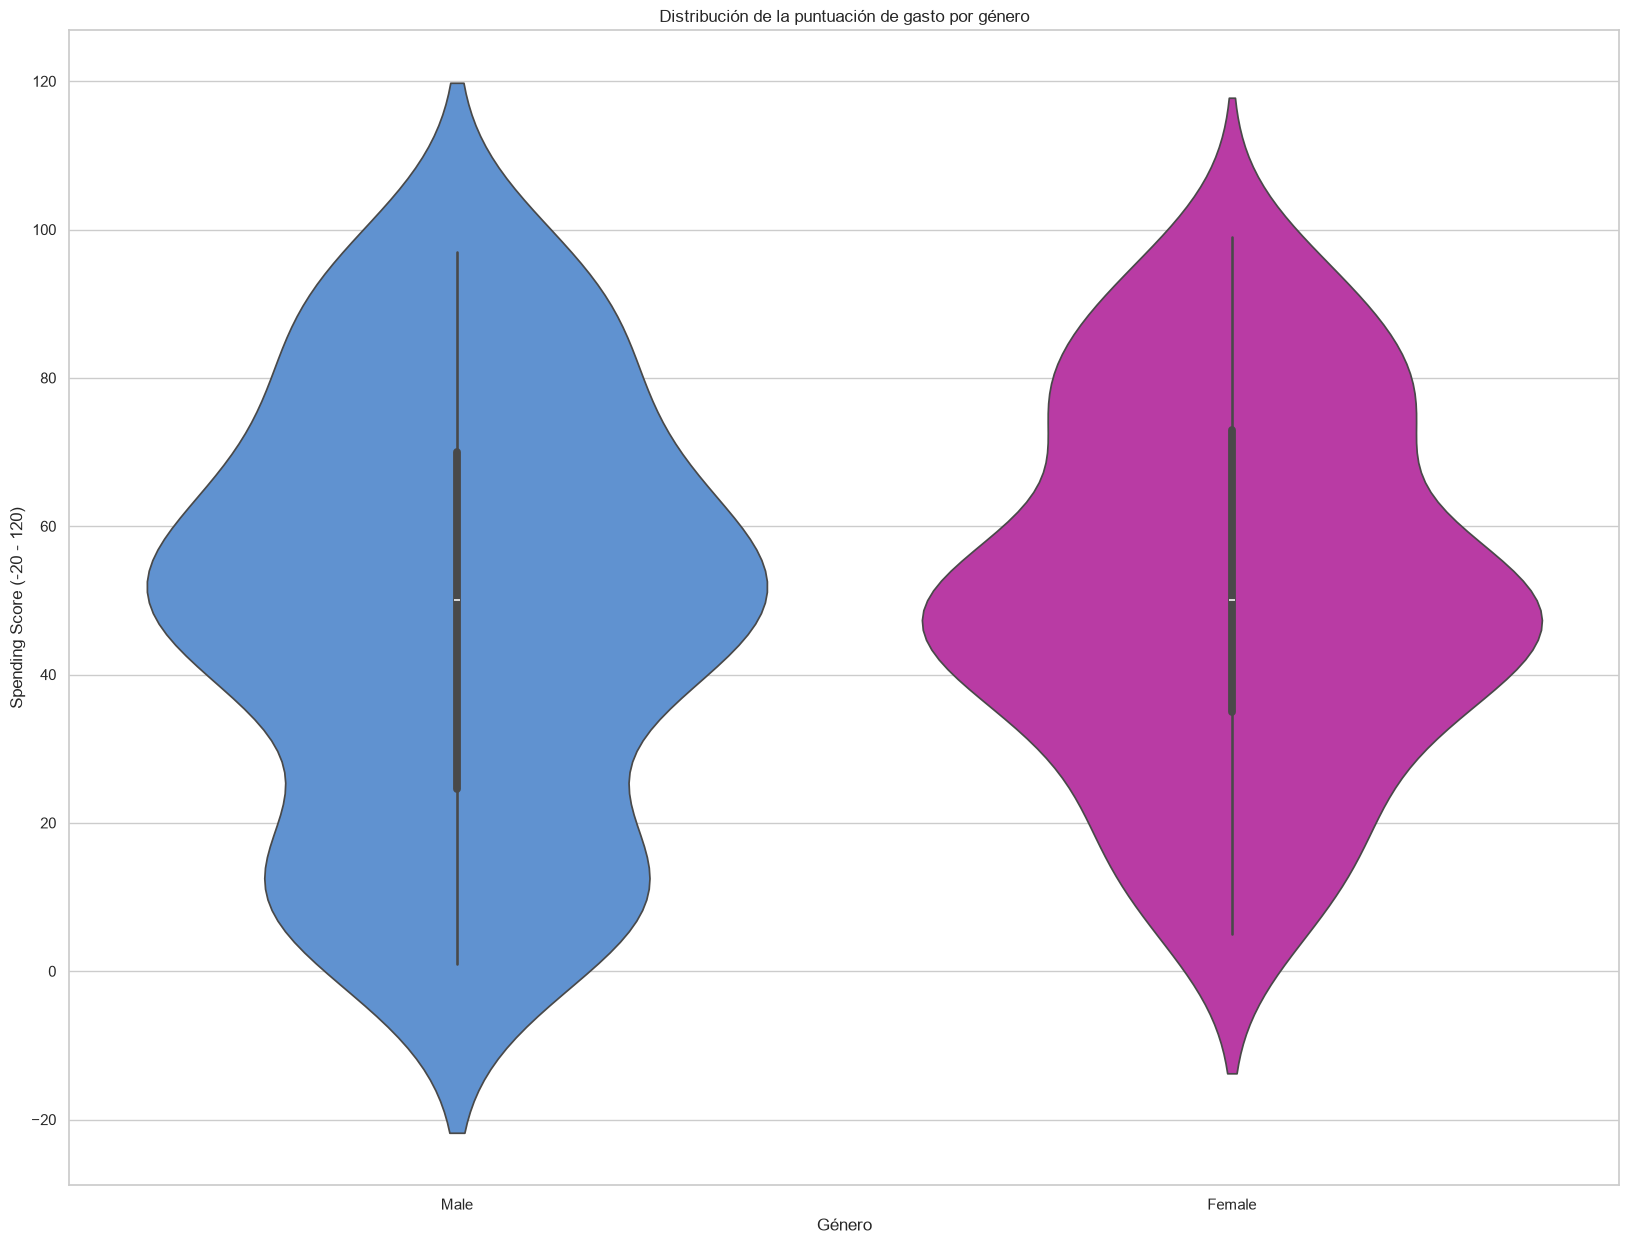

In [50]:
plt.figure(figsize=(20, 15))

sns.violinplot(
    data=df,
    x='Gender',
    y='Spending Score (1-100)',
    palette={'Male': '#4e90e2', 'Female': "#ce26b2"},
)

plt.title('Distribución de la puntuación de gasto por género')
plt.xlabel('Género')
plt.ylabel('Spending Score (-20 - 120)')
plt.show()

In [ ]:
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans



In [52]:
df = pd.read_csv('./data/retailmax.csv')

In [53]:
features = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

In [54]:
df.sample(5, random_state=42)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
95,96,Male,24,60,52
15,16,Male,22,20,79
30,31,Male,60,30,4
158,159,Male,34,78,1
128,129,Male,59,71,11


In [55]:
features.sample(5, random_state=42)

,Age,Annual Income (k$),Spending Score (1-100)
95,24,60,52
15,22,20,79
30,60,30,4
158,34,78,1
128,59,71,11


In [ ]:
#Normaliza caracteristicas para que mantengan una media de 0 y una desviacion estandar de 1.
# Se le llama estandarizacion

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [ ]:

# Inspeccion rapida
type(scaled_features)

numpy.ndarray

In [ ]:
#Tenemos un numpy.ndarray, y por lo tanto no podemos ejecutar el método .head() para ver algunos datos, 
# entonces tendremos que hacerlo a la antigua

scaled_features.shape

(200, 3)

In [ ]:
#Estos ya no los entendemos tan fácilmente, pero sabemos que la primera posición de cada array corresponde a Age,
# la segunda a Annual Income (k$) y finalmente la tercera a Spending Score (1-100).

scaled_features[0:3]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298]])

In [67]:
kmeans = KMeans(n_clusters=5, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(scaled_features)

In [65]:
kmeans

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 3)","[[-0.

In [68]:
clusters

array([1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 4, 1, 0, 1,
       0, 1, 4, 1, 1, 1, 4, 1, 1, 4, 4, 4, 4, 4, 1, 4, 4, 1, 4, 4, 4, 1,
       4, 4, 1, 1, 4, 4, 4, 4, 4, 1, 4, 4, 1, 4, 4, 1, 4, 4, 1, 4, 4, 1,
       1, 4, 4, 1, 4, 4, 1, 1, 4, 1, 4, 1, 1, 4, 4, 1, 4, 1, 4, 4, 4, 4,
       4, 1, 3, 1, 1, 1, 4, 4, 4, 4, 1, 3, 2, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 4, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2], dtype=int32)

In [69]:
kmeans = KMeans(n_clusters=5, init='k-means++', max_iter=300, n_init=10, random_state=42)

In [70]:
kmeans = KMeans(n_clusters=10, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(scaled_features)
clusters

array([9, 3, 9, 3, 9, 3, 9, 3, 7, 3, 7, 3, 7, 3, 9, 3, 9, 3, 7, 3, 9, 3,
       7, 3, 7, 3, 9, 3, 9, 3, 7, 3, 7, 3, 7, 3, 9, 3, 9, 3, 6, 3, 1, 3,
       7, 3, 1, 4, 4, 9, 1, 4, 4, 6, 1, 1, 1, 6, 4, 1, 6, 4, 6, 1, 6, 4,
       1, 6, 4, 4, 6, 1, 6, 6, 6, 4, 1, 1, 4, 1, 6, 1, 6, 1, 4, 1, 1, 4,
       4, 1, 6, 4, 1, 1, 4, 4, 1, 4, 1, 4, 4, 1, 6, 4, 1, 4, 6, 1, 6, 6,
       6, 4, 1, 4, 4, 4, 6, 1, 1, 1, 4, 1, 1, 0, 4, 0, 1, 0, 5, 0, 5, 0,
       4, 0, 2, 0, 5, 0, 2, 0, 5, 0, 4, 0, 2, 0, 5, 0, 2, 0, 5, 0, 5, 0,
       5, 0, 2, 0, 2, 0, 5, 0, 2, 0, 5, 0, 2, 0, 2, 0, 2, 0, 2, 0, 5, 0,
       5, 0, 5, 0, 2, 0, 5, 0, 2, 0, 5, 8, 2, 8, 2, 8, 2, 8, 2, 8, 2, 8,
       2, 8], dtype=int32)

In [73]:
df.sample(5, random_state=42)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
95,96,Male,24,60,52
15,16,Male,22,20,79
30,31,Male,60,30,4
158,159,Male,34,78,1
128,129,Male,59,71,11


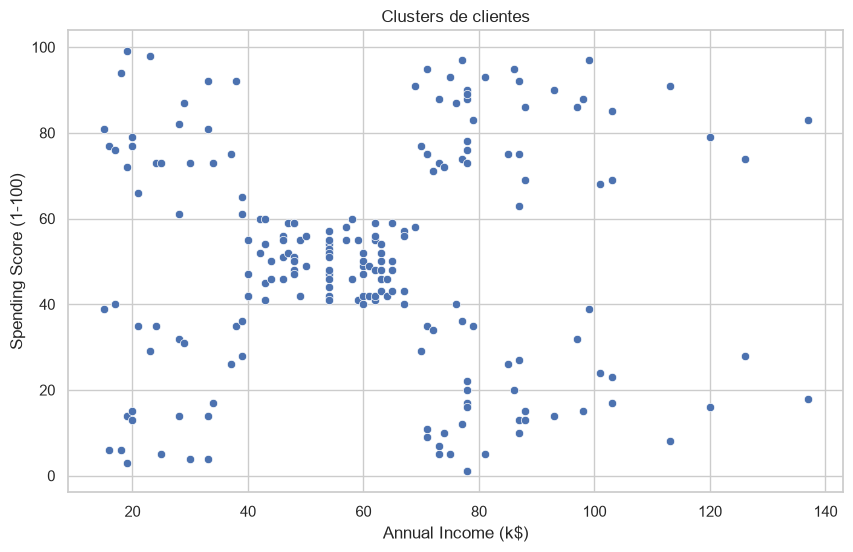

In [90]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', palette='Set1')
plt.title('Clusters de clientes')
plt.show()

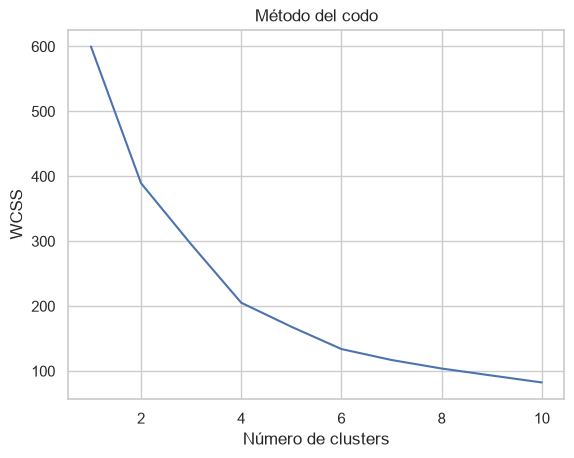

In [91]:
# Función para calcular la Suma de Cuadrados Dentro del Cluster (WCSS)
def calcular_wcss(datos):
    wcss = []
    for n in range(1, 11):
        kmeans = KMeans(n_clusters=n, init='k-means++', max_iter=300, n_init=10, random_state=42)
        kmeans.fit(datos)
        wcss.append(kmeans.inertia_)
    return wcss

# Calcular el WCSS para diferentes números de clusters
wcss = calcular_wcss(scaled_features)

# Graficar el método del codo
plt.plot(range(1, 11), wcss)
plt.title('Método del codo')
plt.xlabel('Número de clusters')
plt.ylabel('WCSS')
plt.show()

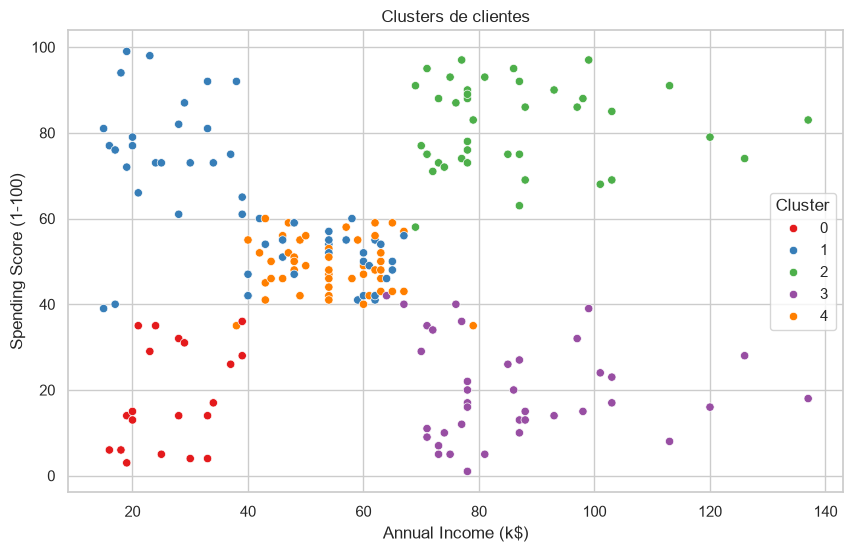

In [92]:
kmeans = KMeans(n_clusters=5, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(scaled_features)
df['Cluster'] = clusters

# mostrar gráfica
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='Annual Income (k$)', y='Spending Score (1-100)', hue='Cluster', palette='Set1')
plt.title('Clusters de clientes')
plt.show()

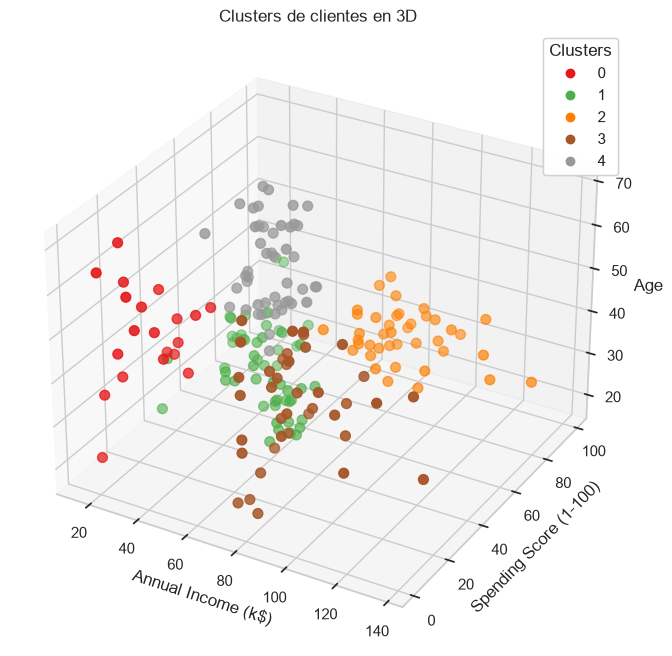

In [93]:
from mpl_toolkits.mplot3d import Axes3D

# Configurar el estilo de Seaborn
sns.set(style="whitegrid")

# Crear una figura en 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Gráfico 3D de dispersión
scatter = ax.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'], df['Age'],
                     c=df['Cluster'], cmap='Set1', s=50)

# Etiquetas de los ejes
ax.set_xlabel('Annual Income (k$)')
ax.set_ylabel('Spending Score (1-100)')
ax.set_zlabel('Age')

# Título de la gráfica
ax.set_title('Clusters de clientes en 3D')

# Añadir la leyenda
legend1 = ax.legend(*scatter.legend_elements(), title="Clusters")
ax.add_artist(legend1)

# Mostrar la gráfica
plt.show()

In [95]:
cluster_analysis = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)', 'Cluster']].groupby('Cluster').mean()
cluster_analysis

,Age,Annual Income (k$),Spending Score (1-100)
Cluster,,,
0,46.250000,26.750000,18.350000
1,25.185185,41.092593,62.240741
2,32.875000,86.100000,81.525000
3,39.871795,86.102564,19.358974
4,55.638298,54.382979,48.851064


In [96]:
for cluster in cluster_analysis.index:
    print(f"Cluster {cluster}:")
    print(f" - Edad media: {cluster_analysis['Age'][cluster]:.2f}")
    print(f" - Ingreso anual medio: {cluster_analysis['Annual Income (k$)'][cluster]:.2f}k$")
    print(f" - Calificación RetailMax: {cluster_analysis['Spending Score (1-100)'][cluster]:.2f}")
    print("===========================================")

Cluster 0:
 - Edad media: 46.25
 - Ingreso anual medio: 26.75k$
 - Calificación RetailMax: 18.35
Cluster 1:
 - Edad media: 25.19
 - Ingreso anual medio: 41.09k$
 - Calificación RetailMax: 62.24
Cluster 2:
 - Edad media: 32.88
 - Ingreso anual medio: 86.10k$
 - Calificación RetailMax: 81.53
Cluster 3:
 - Edad media: 39.87
 - Ingreso anual medio: 86.10k$
 - Calificación RetailMax: 19.36
Cluster 4:
 - Edad media: 55.64
 - Ingreso anual medio: 54.38k$
 - Calificación RetailMax: 48.85


In [97]:
for cluster in cluster_analysis.index:
    print(f"Cluster {cluster}:")
    print(f" - Edad promedio: {cluster_analysis['Age'][cluster]:.2f}")
    print(f" - Ingreso anual promedio: {cluster_analysis['Annual Income (k$)'][cluster]:.2f}k$")
    print(f" - Calificación RetailMax promedio: {cluster_analysis['Spending Score (1-100)'][cluster]:.2f}")
    print("================================")

Cluster 0:
 - Edad promedio: 46.25
 - Ingreso anual promedio: 26.75k$
 - Calificación RetailMax promedio: 18.35
Cluster 1:
 - Edad promedio: 25.19
 - Ingreso anual promedio: 41.09k$
 - Calificación RetailMax promedio: 62.24
Cluster 2:
 - Edad promedio: 32.88
 - Ingreso anual promedio: 86.10k$
 - Calificación RetailMax promedio: 81.53
Cluster 3:
 - Edad promedio: 39.87
 - Ingreso anual promedio: 86.10k$
 - Calificación RetailMax promedio: 19.36
Cluster 4:
 - Edad promedio: 55.64
 - Ingreso anual promedio: 54.38k$
 - Calificación RetailMax promedio: 48.85
